# 06 — NSW vs SA: why is SA so much more volatile?

**Method:**
1. Volatility scorecard by FY: spread, tails, spike hours, negative hours
2. Price distributions side by side, on a clipped and a log scale (a raw histogram would be one bar and a long empty axis)
3. Analyses 1–3 repeated side by side
4. The drivers we can measure from public dispatch data: wind + solar share, curtailment, reliance on imports, and how price behaves as the wind + solar share changes

**Wind + solar** here means **semi-scheduled** generation (utility-scale wind and solar farms) from DISPATCHREGIONSUM:
`SEMISCHEDULE_CLEAREDMW` is what they were dispatched at, and `UIGF` is what they could have produced.
Rooftop solar isn't included; it shows up as lower operational demand instead.

Full FYs (FY23–FY26) are used for comparisons; the June 2022 suspension is excluded.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter

sys.path.append("../src")
from chart_style import apply_style, save_chart, REGION_COLOR, INK_2, MUTED, AXIS

apply_style()
pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_parquet("../data/clean/nem_5min.parquet")
df = df[~df["is_suspension"]].copy()
df["mwh"] = df["TOTALDEMAND"] * 5 / 60
df["value"] = df["RRP"] * df["mwh"]
df["ws_share"] = df["SEMISCHEDULE_CLEAREDMW"] / df["TOTALDEMAND"]            # wind + solar share of demand
df["import_share"] = -df["NETINTERCHANGE"] / df["TOTALDEMAND"]              # > 0 = importing

REGIONS = ["NSW1", "SA1"]
COMPLETE_FY = ["FY23", "FY24", "FY25", "FY26"]
full = df[df["fy"].isin(COMPLETE_FY)]

## 1. Volatility scorecard

Standard deviation is dominated by a handful of cap-priced intervals, so robust measures sit alongside it:
**IQR** (middle-50% spread), the **daily range** (max − min price in a day, median across days), and tail percentiles.

In [2]:
def hours(mask):
    return mask.sum() * 5 / 60


def scorecard(g):
    daily = g.groupby("date")["RRP"]
    return pd.Series({
        "mean": g["RRP"].mean(),
        "median": g["RRP"].median(),
        "std_dev": g["RRP"].std(),
        "IQR": g["RRP"].quantile(0.75) - g["RRP"].quantile(0.25),
        "median_daily_range": (daily.max() - daily.min()).median(),
        "P1": g["RRP"].quantile(0.01),
        "P99": g["RRP"].quantile(0.99),
        "P99.9": g["RRP"].quantile(0.999),
        "hours_>300": hours(g["RRP"] > 300),
        "hours_>1000": hours(g["RRP"] > 1000),
        "hours_>5000": hours(g["RRP"] > 5000),
        "hours_<=0": hours(g["RRP"] <= 0),
    })


score = full.groupby(["fy", "REGIONID"])[["RRP", "date"]].apply(scorecard)
score.unstack("REGIONID").T.style.format("{:,.0f}")

In [3]:
# Ratio SA / NSW for each measure: > 1 means SA is higher
ratio = (score.xs("SA1", level="REGIONID") / score.xs("NSW1", level="REGIONID")).drop(columns=["P1"])
ratio.T.style.format("{:.1f}x")

fy,FY23,FY24,FY25,FY26
mean,0.9x,0.8x,0.8x,1.0x
median,0.8x,0.9x,0.9x,0.7x
std_dev,1.5x,0.8x,0.9x,1.9x
IQR,2.2x,2.2x,2.2x,1.8x
median_daily_range,1.4x,1.2x,1.1x,1.7x
P99,1.1x,1.2x,1.1x,1.3x
P99.9,8.2x,0.4x,0.9x,6.5x
hours_>300,1.3x,2.0x,1.4x,3.3x
hours_>1000,2.3x,0.7x,0.9x,4.4x
hours_>5000,2.9x,0.6x,1.1x,2.6x


## 2. Distributions

**Left:** the body of the distribution, clipped to −$200 to $500 (share of intervals outside the window is printed).
**Right:** the tail as an *exceedance curve*: the share of intervals priced above each level, on log–log axes.
A fatter tail sits higher and to the right.

NSW1: 0.7% of intervals outside $-200 to $500 (piled into the end bins)
SA1: 1.4% of intervals outside $-200 to $500 (piled into the end bins)


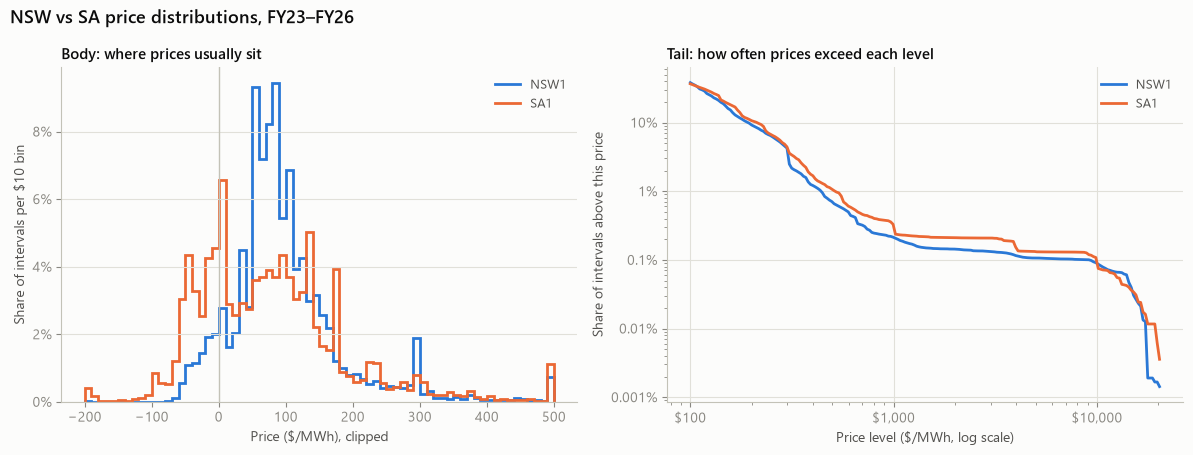

In [4]:
LOW, HIGH, STEP = -200, 500, 10
bins = np.arange(LOW, HIGH + STEP, STEP)
levels = np.logspace(2, np.log10(20_300), 200)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
for region in REGIONS:
    p = full.loc[full["REGIONID"] == region, "RRP"]
    share, _ = np.histogram(p.clip(LOW, HIGH), bins=bins)
    ax1.stairs(share / len(p), bins, color=REGION_COLOR[region], lw=2, label=region)
    outside = ((p < LOW) | (p > HIGH)).mean()
    print(f"{region}: {outside:.1%} of intervals outside ${LOW} to ${HIGH} (piled into the end bins)")

    # Share of intervals above each level: 1 - (number at or below the level) / total
    exceed = 1 - np.searchsorted(np.sort(p.to_numpy()), levels, side="right") / len(p)
    ax2.plot(levels, exceed, color=REGION_COLOR[region], lw=2, label=region)

ax1.axvline(0, color=AXIS, lw=1)
ax1.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax1.set_xlabel("Price ($/MWh), clipped")
ax1.set_ylabel("Share of intervals per $10 bin")
ax1.set_title("Body: where prices usually sit")

ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v * 100:g}%"))
ax2.set_xlabel("Price level ($/MWh, log scale)")
ax2.set_ylabel("Share of intervals above this price")
ax2.set_title("Tail: how often prices exceed each level")
ax2.grid(True, which="major", axis="both", color="#e1e0d9", lw=0.8)

for ax in (ax1, ax2):
    ax.legend(frameon=False, fontsize=9, labelcolor=INK_2)
fig.suptitle("NSW vs SA price distributions, FY23–FY26", x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.tight_layout()
save_chart(fig, "../charts/06_distributions.png")

**What it shows:** _your sentence_

**Why it matters to a trader:** _your sentence_

## 3. Analyses 1–3 side by side

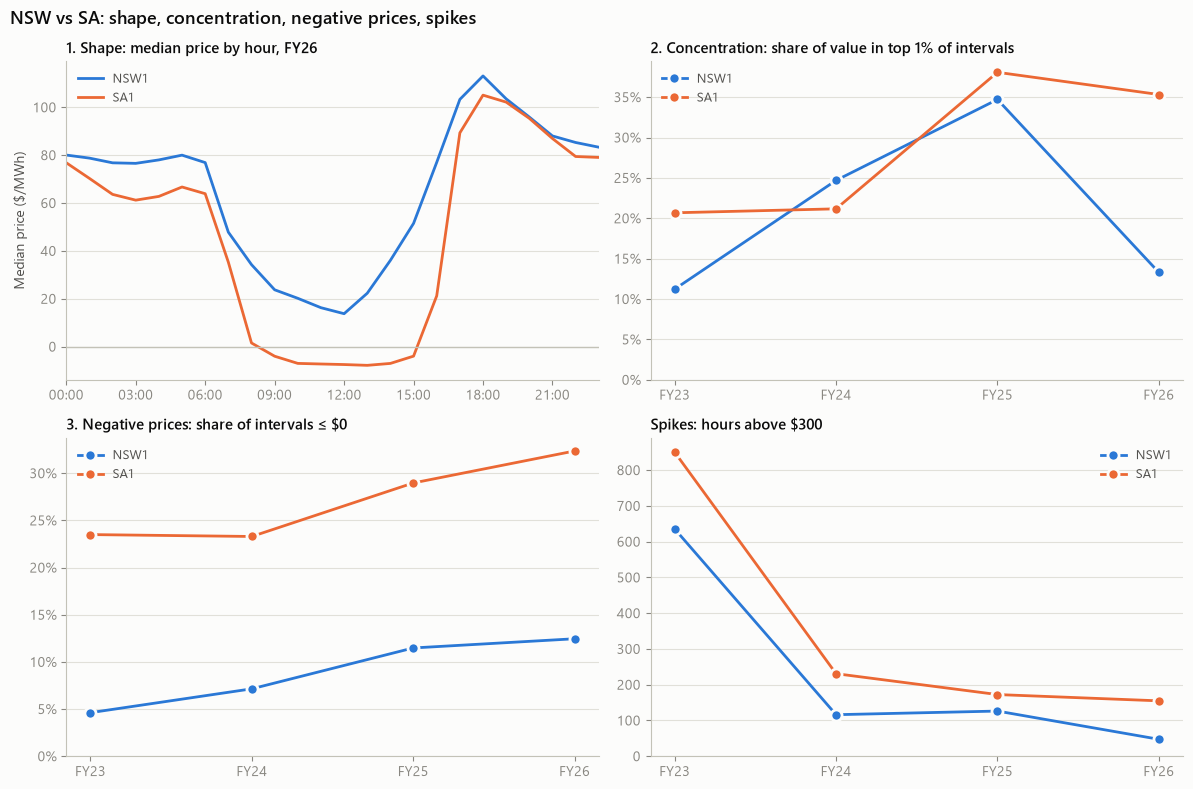

In [5]:
def top_share(g, pct=0.01):
    n = int(round(len(g) * pct))
    return g.nlargest(n, "RRP")["value"].sum() / g["value"].sum()


by_fy = full.groupby(["fy", "REGIONID"])
compare = pd.DataFrame({
    "top_1%_share": by_fy[["RRP", "value"]].apply(top_share),
    "share_<=0": by_fy["RRP"].apply(lambda p: (p <= 0).mean()),
    "hours_>300": by_fy["RRP"].apply(lambda p: hours(p > 300)),
}).unstack("REGIONID")
latest_shape = df[df["fy"] == "FY26"].groupby(["REGIONID", "hour"])["RRP"].median().unstack("REGIONID")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
ax = axes[0, 0]
for region in REGIONS:
    ax.plot(latest_shape.index, latest_shape[region], color=REGION_COLOR[region], lw=2, label=region)
ax.axhline(0, color=AXIS, lw=1)
ax.set_xticks(range(0, 24, 3), [f"{h:02d}:00" for h in range(0, 24, 3)])
ax.set_xlim(0, 23)
ax.set_ylabel("Median price ($/MWh)")
ax.set_title("1. Shape: median price by hour, FY26")

panels = [
    (axes[0, 1], "top_1%_share", "2. Concentration: share of value in top 1% of intervals", PercentFormatter(1, decimals=0)),
    (axes[1, 0], "share_<=0", "3. Negative prices: share of intervals ≤ $0", PercentFormatter(1, decimals=0)),
    (axes[1, 1], "hours_>300", "Spikes: hours above $300", None),
]
for ax, col, title, fmt in panels:
    for region in REGIONS:
        s = compare[col][region]
        ax.plot(s.index, s.values, color=REGION_COLOR[region], lw=2, marker="o", ms=8, mec="#fcfcfb", mew=2, label=region)
    ax.set_ylim(0, None)
    ax.set_title(title)
    if fmt:
        ax.yaxis.set_major_formatter(fmt)

for ax in axes.flat:
    ax.legend(frameon=False, fontsize=9, labelcolor=INK_2)
fig.suptitle("NSW vs SA: shape, concentration, negative prices, spikes", x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.tight_layout()
save_chart(fig, "../charts/06_side_by_side.png")

In [6]:
compare.style.format({c: "{:.0%}" for c in compare.columns if c[0] != "hours_>300"} | {
    c: "{:,.0f}" for c in compare.columns if c[0] == "hours_>300"})

## 4. Why: the drivers we can measure

Three structural differences show up directly in AEMO's dispatch data:
- **Wind + solar share:** how much of the region's demand utility wind and solar cover on average
- **Curtailment:** how much wind + solar was available but not dispatched (`UIGF` − `SEMISCHEDULE_CLEAREDMW`), usually because prices went negative or the network couldn't take it
- **Import reliance:** how often the region leans on its interconnectors for a big share of demand

In [7]:
drivers = full.groupby(["fy", "REGIONID"]).apply(lambda g: pd.Series({
    "avg_demand_MW": g["TOTALDEMAND"].mean(),
    "wind_solar_share": g["SEMISCHEDULE_CLEAREDMW"].sum() / g["TOTALDEMAND"].sum(),
    "curtailment": 1 - g["SEMISCHEDULE_CLEAREDMW"].sum() / g["UIGF"].sum(),
    "intervals_wind_solar_>_demand": (g["ws_share"] > 1).mean(),
    "intervals_importing_>20%": (g["import_share"] > 0.2).mean(),
    "intervals_exporting_>20%": (g["import_share"] < -0.2).mean(),
}), include_groups=False).unstack("REGIONID")
drivers.style.format({c: "{:,.0f}" if c[0] == "avg_demand_MW" else "{:.0%}" for c in drivers.columns})

### Price vs wind + solar share

The mechanism in one chart: bin every interval by how much of demand wind + solar were covering, then look at the
median price and the chance of a spike in each bin. If SA's volatility comes from its renewable share, SA should
spend much more time at both ends of the x-axis, where prices collapse (high share) or spike (low share).

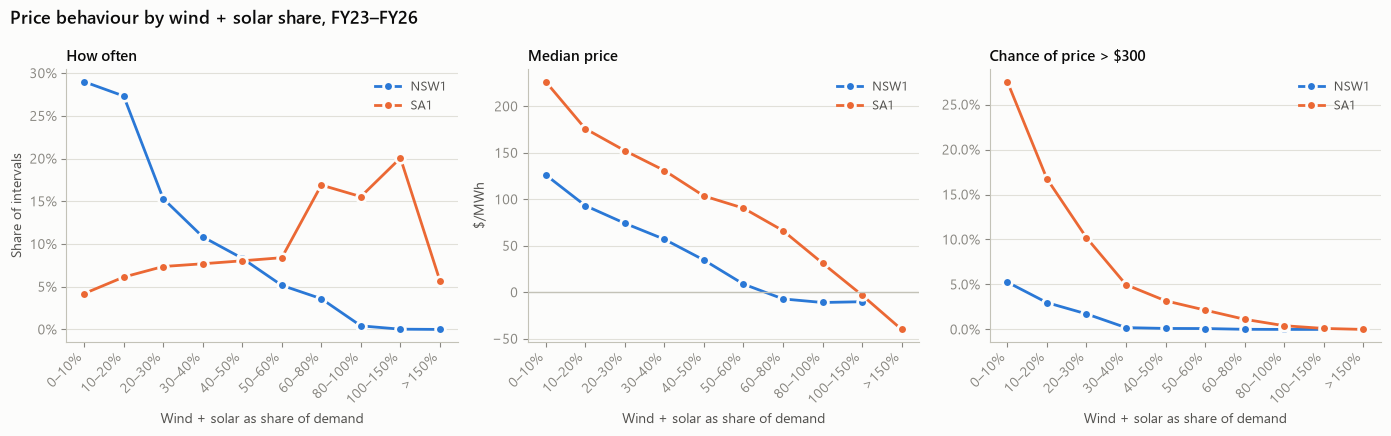

In [8]:
BIN_EDGES = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.5, np.inf]
BIN_LABELS = ["0–10%", "10–20%", "20–30%", "30–40%", "40–50%", "50–60%", "60–80%", "80–100%", "100–150%", ">150%"]
full = full.assign(ws_bin=pd.cut(full["ws_share"], BIN_EDGES, labels=BIN_LABELS, right=False))

by_bin = full.groupby(["REGIONID", "ws_bin"], observed=False)["RRP"].agg(
    time_share="size",
    median_price="median",
    spike_chance=lambda p: (p > 300).mean(),
)
by_bin["time_share"] = by_bin["time_share"] / by_bin.groupby(level="REGIONID")["time_share"].transform("sum")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True)
for region in REGIONS:
    b = by_bin.loc[region]
    x = np.arange(len(BIN_LABELS))
    axes[0].plot(x, b["time_share"], color=REGION_COLOR[region], lw=2, marker="o", ms=7, mec="#fcfcfb", mew=2, label=region)
    axes[1].plot(x, b["median_price"], color=REGION_COLOR[region], lw=2, marker="o", ms=7, mec="#fcfcfb", mew=2, label=region)
    axes[2].plot(x, b["spike_chance"], color=REGION_COLOR[region], lw=2, marker="o", ms=7, mec="#fcfcfb", mew=2, label=region)

axes[0].set_title("How often")
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylabel("Share of intervals")
axes[1].set_title("Median price")
axes[1].axhline(0, color=AXIS, lw=1)
axes[1].set_ylabel("$/MWh")
axes[2].set_title("Chance of price > $300")
axes[2].yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
for ax in axes:
    ax.set_xticks(range(len(BIN_LABELS)), BIN_LABELS, rotation=45, ha="right")
    ax.set_xlabel("Wind + solar as share of demand")
    ax.legend(frameon=False, fontsize=9, labelcolor=INK_2)
fig.suptitle("Price behaviour by wind + solar share, FY23–FY26", x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.tight_layout()
save_chart(fig, "../charts/06_price_vs_wind_solar.png")

In [9]:
by_bin.unstack("REGIONID").style.format({c: "{:.1%}" if c[0] != "median_price" else "{:,.0f}" for c in by_bin.unstack("REGIONID").columns})

**What it shows:** _your sentence_

**Why it matters to a trader:** _your sentence_

**Size matters too.** SA's average demand is about 1.3 GW against NSW's ~7.5 GW. The same 200 MW unit trip or
200 MW interconnector limit change is ~15% of SA's demand and under 3% of NSW's, so the same shock moves SA's price much more.

## Try it yourself

- Change the spike threshold in `by_bin` from $300 to $1,000
- Re-run the scorecard on FY22 (crisis year): is SA still more volatile on every measure?
- Split section 4 by season: is the low-wind/high-price link stronger in winter?